# E-commerce Product Delivery Prediction

In [24]:
# Load the source data and libraries used for analysis and charts.
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

working_dir = Path.cwd()
project_root = working_dir if (working_dir / "data" / "E_Commerce.csv").exists() else working_dir.parent
df = pd.read_csv(project_root / "data" / "E_Commerce.csv")


In [25]:
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10999, 12)


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [26]:
print("Column types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isna().sum())

Column types:
ID                     int64
Warehouse_block          str
Mode_of_Shipment         str
Customer_care_calls    int64
Customer_rating        int64
Cost_of_the_Product    int64
Prior_purchases        int64
Product_importance       str
Gender                   str
Discount_offered       int64
Weight_in_gms          int64
Reached.on.Time_Y.N    int64
dtype: object

Missing values per column:
ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64


# EDA

### Numeric Feature Distributions

These histograms show the ranges and concentrations of the numeric inputs before modeling. They describe the inputs overall; they do not compare delivery outcomes.


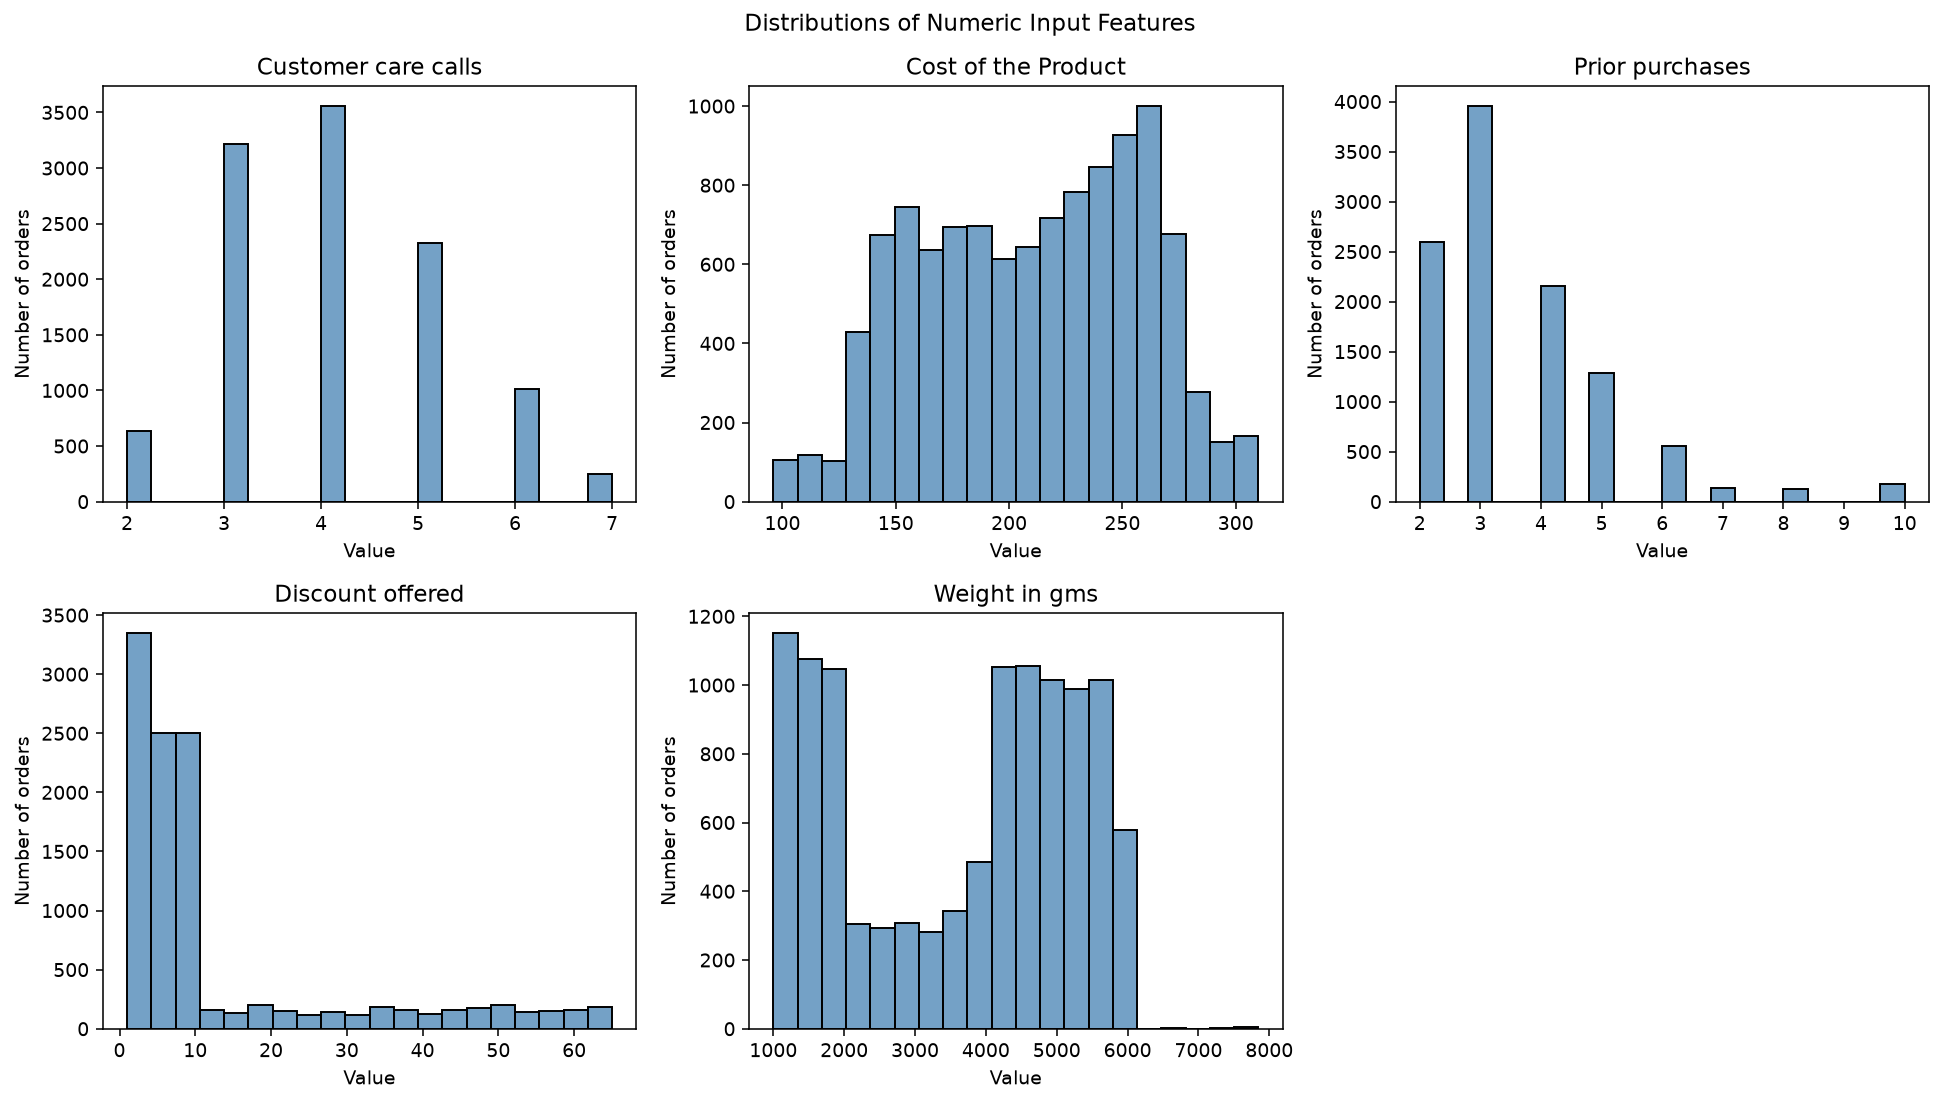

In [ ]:
# Plot each numeric input separately so their different scales remain readable.
numeric_features = ["Customer_care_calls", "Cost_of_the_Product", "Prior_purchases", "Discount_offered", "Weight_in_gms"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for feature, ax in zip(numeric_features, axes.flat):
    sns.histplot(data=df, x=feature, bins=20, ax=ax, color="steelblue")
    ax.set_title(feature.replace("_", " "))
    ax.set_xlabel("Value")
    ax.set_ylabel("Number of orders")
axes.flat[len(numeric_features)].set_visible(False)
fig.suptitle("Distributions of Numeric Input Features")
plt.tight_layout()
plt.show()


**Interpretation:** The inputs have different units and ranges. Customer-care calls range from 2 to 7, product cost from 96 to 310, discounts from 1 to 65, and weight from 1,001 to 7,846 grams. Discount and prior purchases have upper ranges well above their medians. StandardScaler is used for numeric inputs during preprocessing.


### Delivery Outcome Counts

In [27]:
print(df["Reached.on.Time_Y.N"].value_counts().rename({
    1: "Late",
    0: "On time"
}))

Reached.on.Time_Y.N
Late       6563
On time    4436
Name: count, dtype: int64


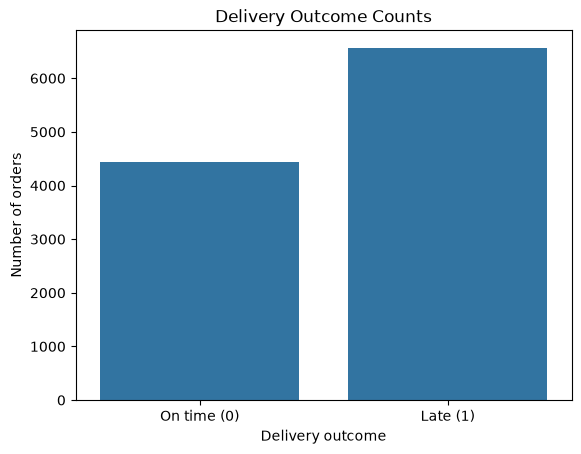

In [28]:
sns.countplot(data=df, x="Reached.on.Time_Y.N", order=[0, 1])

plt.xticks([0, 1], ["On time (0)", "Late (1)"])
plt.title("Delivery Outcome Counts")
plt.xlabel("Delivery outcome")
plt.ylabel("Number of orders")
plt.show()

**Interpretation:** The dataset contains 6,563 late orders and 4,436 on-time orders. About 59.7% of the orders are labeled late, so the outcomes are not evenly split. This is why the model comparison should include precision, recall and F1-score, not accuracy alone.


### Late Delivery Rate by Shipment Mode

In [29]:
late_rate = (
    df.groupby("Mode_of_Shipment")["Reached.on.Time_Y.N"]
      .mean() * 100
)

print(late_rate.round(1))

Mode_of_Shipment
Flight    60.2
Road      58.8
Ship      59.8
Name: Reached.on.Time_Y.N, dtype: float64


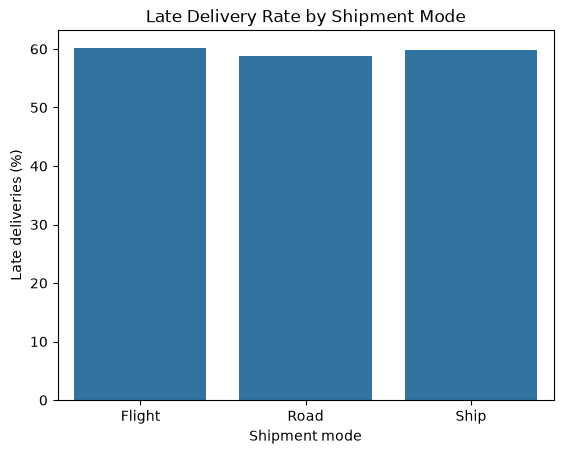

In [30]:
late_rate = (
    df.groupby("Mode_of_Shipment")["Reached.on.Time_Y.N"]
      .mean()
      .mul(100)
)

sns.barplot(x=late_rate.index, y=late_rate.values)
plt.title("Late Delivery Rate by Shipment Mode")
plt.xlabel("Shipment mode")
plt.ylabel("Late deliveries (%)")
plt.show()

**Interpretation:** Late-delivery rates are close across shipment modes: Flight 60.2%, Ship 59.8% and Road 58.8%. The chart shows percentages, so it compares rates despite the shipment groups having very different numbers of orders. These small differences are descriptive and do not establish that shipment mode causes delay.


### Late Delivery Rate by Warehouse Block

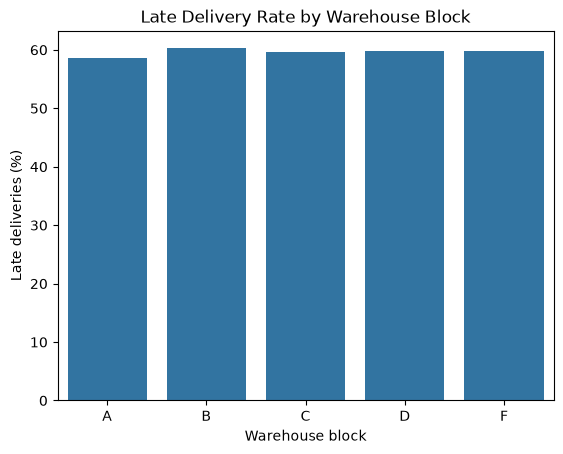

In [31]:
late_rate = (
    df.groupby("Warehouse_block")["Reached.on.Time_Y.N"]
      .mean()
      .mul(100)
)

sns.barplot(x=late_rate.index, y=late_rate.values)
plt.title("Late Delivery Rate by Warehouse Block")
plt.xlabel("Warehouse block")
plt.ylabel("Late deliveries (%)")
plt.show()

**Interpretation:** Late-delivery rates range from 58.6% for warehouse A to 60.2% for warehouse B; C, D and F are about 59.7–59.8%. The rates are similar across blocks, so warehouse block alone shows little separation in this dataset. This is a descriptive comparison, not evidence of cause.


### Late Delivery Rate by Product Importance

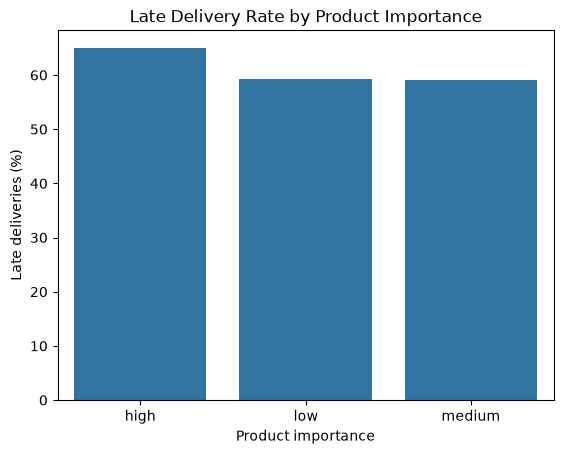

In [32]:
late_rate = (
    df.groupby("Product_importance")["Reached.on.Time_Y.N"]
      .mean()
      .mul(100)
)

sns.barplot(x=late_rate.index, y=late_rate.values)
plt.title("Late Delivery Rate by Product Importance")
plt.xlabel("Product importance")
plt.ylabel("Late deliveries (%)")
plt.show()

**Interpretation:** The late rate is 65.0% for high-importance products, compared with 59.3% for low and 59.0% for medium importance. The high-importance group has fewer orders (948) than the low and medium groups, so this difference should be treated as an observed association rather than proof that product importance causes delays.


### Numeric Features by Delivery Outcome

These boxplots compare each numeric input for orders labeled On time and Late. Outlier points are hidden to make the central ranges easier to compare; the boxes show quartiles and medians.


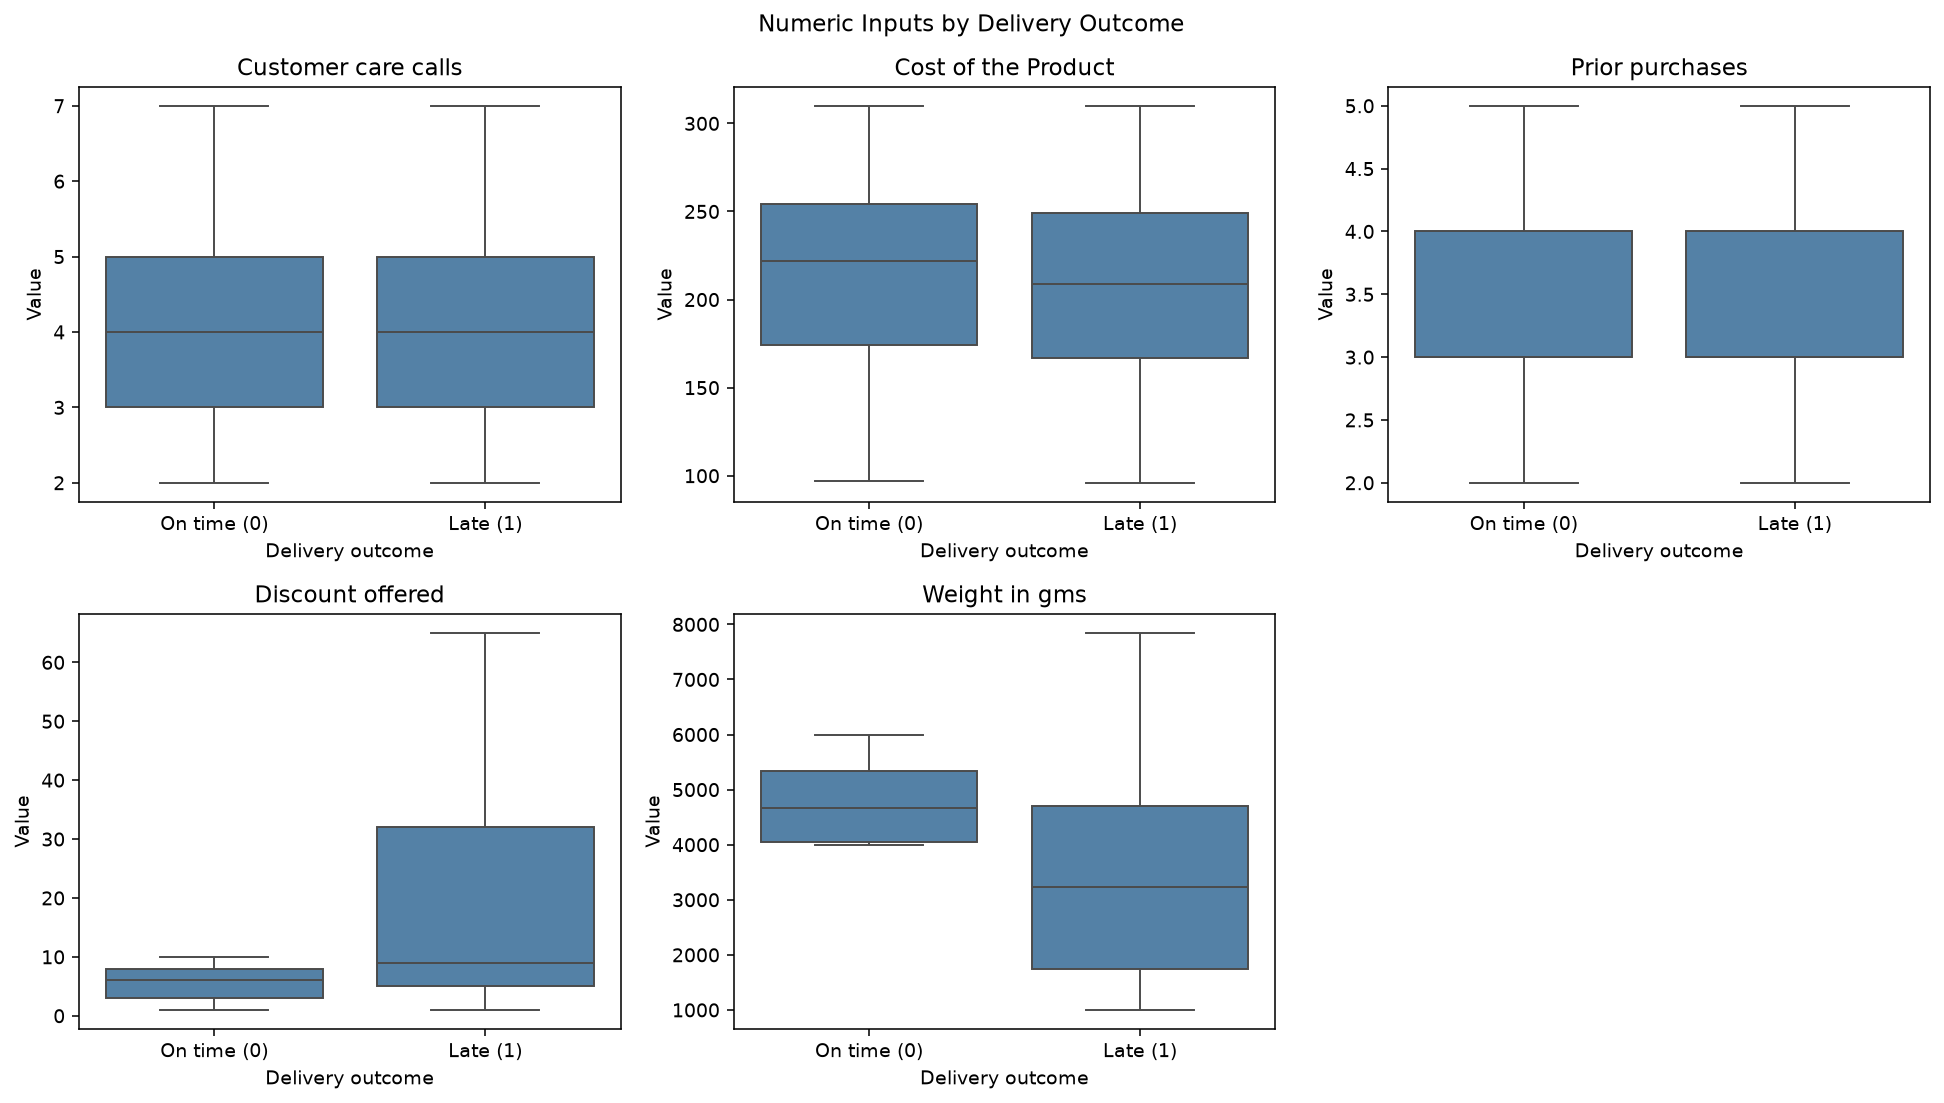

In [ ]:
# Compare numeric input distributions for the actual delivery classes.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for feature, ax in zip(numeric_features, axes.flat):
    sns.boxplot(data=df, x="Reached.on.Time_Y.N", y=feature, order=[0, 1], showfliers=False, ax=ax, color="steelblue")
    ax.set_title(feature.replace("_", " "))
    ax.set_xticks([0, 1], ["On time (0)", "Late (1)"])
    ax.set_xlabel("Delivery outcome")
    ax.set_ylabel("Value")
axes.flat[len(numeric_features)].set_visible(False)
fig.suptitle("Numeric Inputs by Delivery Outcome")
plt.tight_layout()
plt.show()


**Interpretation:** Median weight is higher for On time orders (4,674 g) than Late orders (3,231 g). The Late group has a higher median discount (9 versus 6), while the On time group has a higher median product cost (222 versus 209). Customer-care calls and prior purchases have the same medians in both groups. The distributions overlap, so these are descriptive patterns and do not establish cause or guarantee an individual outcome.


## Preprocessing


In [33]:
X = df.drop(columns=[
    "Reached.on.Time_Y.N",
    "ID",
    "Customer_rating"
])
y = df["Reached.on.Time_Y.N"]

print("Feature data shape:", X.shape)
print("Target shape:", y.shape)

Feature data shape: (10999, 9)
Target shape: (10999,)


In [34]:
# Hold out test rows and preserve the target-class proportions.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 8799
Testing rows: 2200


In [35]:
# Scale numeric features and encode categorical features.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = X_train.select_dtypes(include="object").columns
numerical_features = X_train.select_dtypes(exclude="object").columns

preprocessor = ColumnTransformer(
    transformers=[
        ("numbers", StandardScaler(), numerical_features),
        ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Categorical features:", list(categorical_features))
print("Numerical features:", list(numerical_features))

Categorical features: ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']
Numerical features: ['Customer_care_calls', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']


C:\Users\VICTUS\AppData\Local\Temp\ipykernel_28748\3699467133.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include="object").columns


## Model Training and Evaluation

Each classifier is combined with the preprocessing transformer in one pipeline, fitted on training rows, and evaluated on held-out test rows.


In [36]:
# Define comparable classifiers with preprocessing kept inside each pipeline.
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Logistic Regression": Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(n_estimators=100, random_state=42))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ])
}

print("Models ready:", list(models.keys()))

Models ready: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'K-Nearest Neighbors']


In [37]:
# Fit each complete pipeline using training data only.
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")
    

Logistic Regression trained
Decision Tree trained
Random Forest trained
K-Nearest Neighbors trained


In [38]:
# Evaluate every fitted model on the held-out test data.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (late)": precision_score(y_test, predictions),
        "Recall (late)": recall_score(y_test, predictions),
        "F1-score (late)": f1_score(y_test, predictions)
    })

comparison = pd.DataFrame(results).sort_values(
    by="F1-score (late)",
    ascending=False
)

display(comparison.round(3))

,Model,Accuracy,Precision (late),Recall (late),F1-score (late)
1,Decision Tree,0.642,0.702,0.694,0.698
2,Random Forest,0.656,0.745,0.644,0.691
0,Logistic Regression,0.637,0.706,0.671,0.688
3,K-Nearest Neighbors,0.616,0.694,0.639,0.665


**Model comparison takeaway:** Decision Tree has the highest late-class F1-score (0.698), with 70.2% precision and 69.4% recall. Random Forest has the highest overall accuracy (65.6%) and late precision (74.5%), but its late recall is lower (64.4%). Decision Tree was selected for the app because it gives the best balance of precision and recall for identifying late orders, as measured by F1.


In [39]:
# Print per-class precision, recall, F1-score, and support.
from sklearn.metrics import classification_report

for name, model in models.items():
    predictions = model.predict(X_test)

    print(f"\n{name}")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["On time", "Late"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

     On time       0.55      0.59      0.57       887
        Late       0.71      0.67      0.69      1313

    accuracy                           0.64      2200
   macro avg       0.63      0.63      0.63      2200
weighted avg       0.64      0.64      0.64      2200


Decision Tree
              precision    recall  f1-score   support

     On time       0.55      0.56      0.56       887
        Late       0.70      0.69      0.70      1313

    accuracy                           0.64      2200
   macro avg       0.63      0.63      0.63      2200
weighted avg       0.64      0.64      0.64      2200


Random Forest
              precision    recall  f1-score   support

     On time       0.56      0.67      0.61       887
        Late       0.75      0.64      0.69      1313

    accuracy                           0.66      2200
   macro avg       0.65      0.66      0.65      2200
weighted avg       0.67

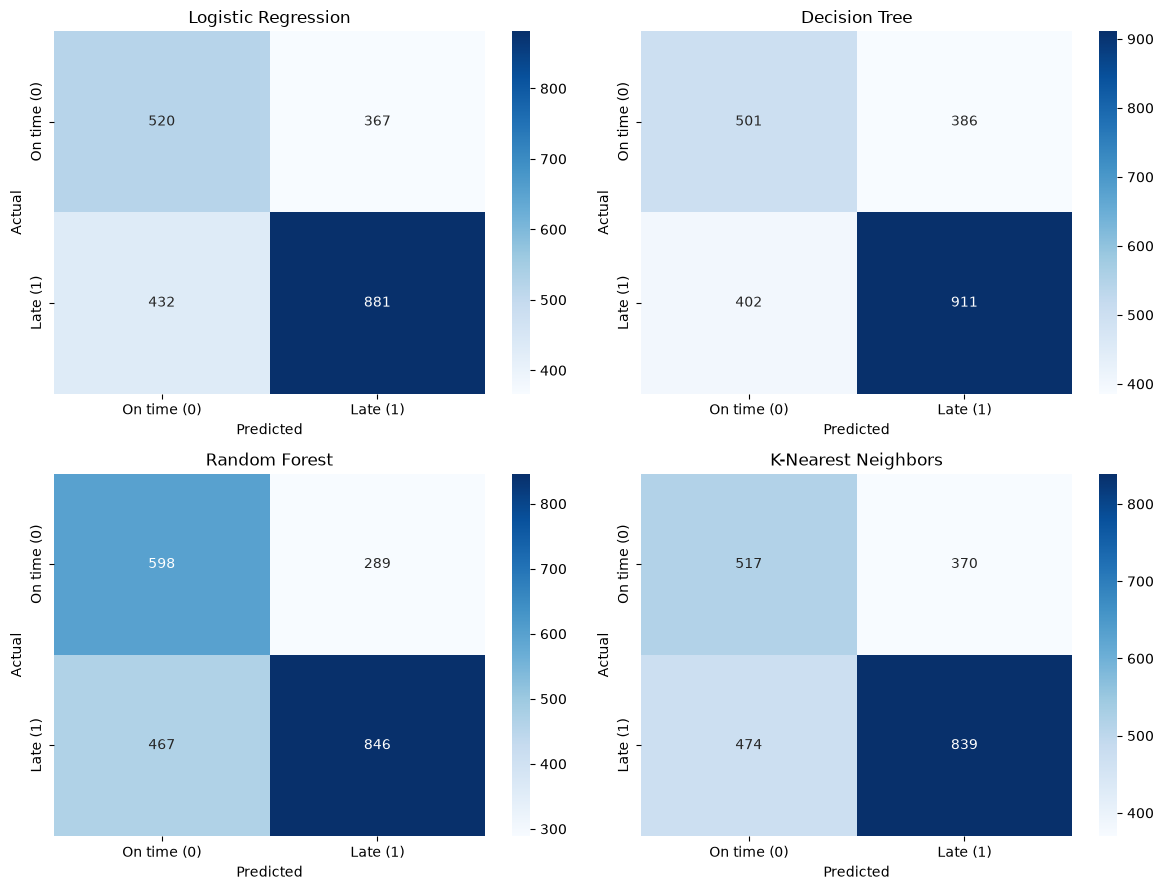

In [40]:
# Compare actual and predicted classes for every model.
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for (name, model), ax in zip(models.items(), axes.flat):
    predictions = model.predict(X_test)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["On time (0)", "Late (1)"],
        yticklabels=["On time (0)", "Late (1)"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

**How to read the confusion matrices:** Rows are actual outcomes and columns are predicted outcomes. The top-left and bottom-right cells are correct predictions; the other two cells are mistakes. For the late class, a false negative is a late order predicted on time, while a false positive is an on-time order predicted late. The Random Forest misses fewer on-time orders as late (289 false positives) but misses more actual late orders (467 false negatives) than the Decision Tree (386 and 402).


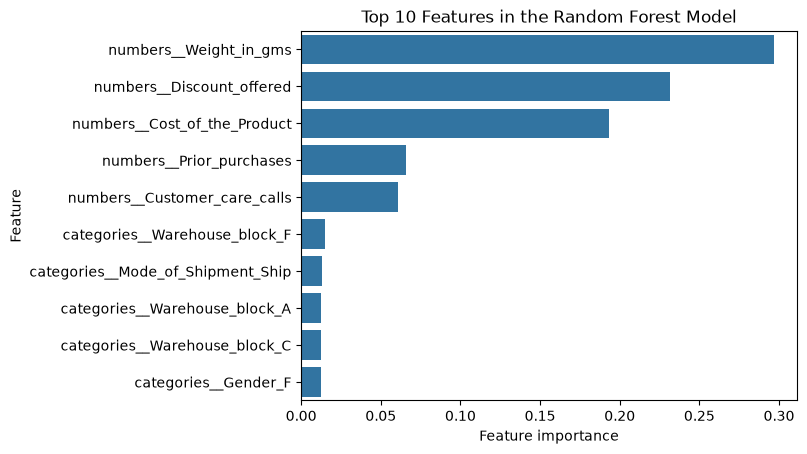

In [41]:
# Read the Random Forest importance scores for the encoded input features.
rf_pipeline = models["Random Forest"]

feature_names = (
    rf_pipeline.named_steps["preprocessing"]
    .get_feature_names_out()
)

importances = rf_pipeline.named_steps["classifier"].feature_importances_

top_features = (
    pd.Series(importances, index=feature_names)
      .sort_values(ascending=False)
      .head(10)
)

sns.barplot(x=top_features.values, y=top_features.index)
plt.title("Top 10 Features in the Random Forest Model")
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.show()

**Interpretation:** Weight (0.297), discount offered (0.232) and product cost (0.193) are the three largest Random Forest importance scores; together they account for about 72.2% of the importance shown. Prior purchases (0.066) and customer-care calls (0.061) are next. These scores describe how the fitted Random Forest used the inputs; they do not show that changing an input will cause a delivery to be late.


In [42]:
# Save dashboard and evaluation artifacts in their organized folders.
app_dir = project_root / "app"
evaluation_dir = project_root / "evaluation"
app_dir.mkdir(parents=True, exist_ok=True)
evaluation_dir.mkdir(parents=True, exist_ok=True)

status_map = {0: "On time", 1: "Late"}

# Delivery data for charts
dashboard_data = df.drop(columns=["ID", "Customer_rating"]).copy()
dashboard_data["Delivery_Status"] = (
    dashboard_data["Reached.on.Time_Y.N"].map(status_map)
)
dashboard_data.to_csv(app_dir / "delivery_dashboard_data.csv", index=False)

# Model comparison scores
comparison.to_csv(app_dir / "model_comparison.csv", index=False)

# Actual and predicted outcomes for every model
prediction_tables = []

for model_name, model in models.items():
    predictions = model.predict(X_test)
    table = X_test.reset_index(drop=True).copy()
    table["Actual"] = y_test.reset_index(drop=True).map(status_map)
    table["Predicted"] = pd.Series(predictions).map(status_map)
    table["Model"] = model_name
    prediction_tables.append(table)

all_predictions = pd.concat(prediction_tables, ignore_index=True)
all_predictions.to_csv(evaluation_dir / "model_test_predictions.csv", index=False)

# Random Forest feature importance
top_features.rename_axis("Feature").reset_index(
    name="Importance"
).to_csv(app_dir / "feature_importance.csv", index=False)

print("Dashboard and evaluation files saved.")


Dashboard files saved.


In [43]:
import joblib

best_model = models["Decision Tree"]
joblib.dump(best_model, app_dir / "delivery_prediction_model.joblib")

print("Model saved for the Streamlit app.")


Model saved for the Streamlit app.
